# FEG: residual convergence for monotone Lipschitz operators

Let $A$ be monotone and $L$-Lipschitz on a real finite-dimensional Euclidean space, with $L>0$, $A(x_{\star})=0$, and $\|x_{0}-x_{\star}\|^2\le R^2$, $R\ge0$. For integer $N\ge1$, the metric is $\|A(x_{N})\|^2$.

For $k=0,\ldots,N-1$,
$$x_{k+1/2}=x_{k}+\frac{x_{0}-x_{k}}{k+1}-\frac{k}{(k+1)L}A(x_{k}),$$
$$x_{k+1}=x_{k}+\frac{x_{0}-x_{k}}{k+1}-\frac1L A(x_{k+1/2}).$$
At $k=0$, $x_{1/2}=x_{0}$ is one shared point.

## Proof Statement

### Theorem
Under the assumptions and updates above, for every integer $N\ge1$,
$$\|A(x_{N})\|^{2}\le\frac{4L^{2}R^{2}}{N^{2}}.$$
An exact nonincreasing Lyapunov certificate is $V_{0}=0$ and
$$V_{k}=\frac{2k^{2}}{N^{2}}\|A(x_{k})\|^{2}+\frac{4kL}{N^{2}}\langle A(x_{k}),x_{k}-x_{0}\rangle,\qquad 1\le k\le N.$$
No function-value or constant terms are present. The same formula applies at the terminal index. The bound is valid at $N=1$, although the numerical PEP value there is smaller.

### Proof outline
Write
$$M(u,v)=-\langle A(u)-A(v),u-v\rangle\le0,\qquad Q(u,v)=\|A(u)-A(v)\|^{2}-L^{2}\|u-v\|^{2}\le0.$$
For $V_{k}=2k^{2}\|A(x_{k})\|^{2}/N^{2}+4kL\langle A(x_{k}),x_{k}-x_{0}\rangle/N^{2}$, the initial update $x_{1}=x_{0}-A(x_{0})/L$ gives
$$V_{1}=\frac{2}{N^{2}}Q(x_{0},x_{1})\le0=V_{0}.$$
For every $1\le k\le N-1$, the two algorithm updates give the exact identity
$$V_{k+1}-V_{k}=\frac{4Lk(k+1)}{N^{2}}M(x_{k},x_{k+1})+\frac{2(k+1)^{2}}{N^{2}}Q(x_{k+1/2},x_{k+1})\le0.$$
Both multipliers are positive on this range, so $V_{N}\le0$. Set
$$S_{N}=\left\|A(x_{N})-\frac{2L}{N}(x_{0}-x_{\star})\right\|^{2}\ge0.$$
Since $A(x_{\star})=0$, the terminal identity is
$$\|A(x_{N})\|^{2}-\frac{4L^{2}R^{2}}{N^{2}}=V_{N}+\frac{4L}{N}M(x_{N},x_{\star})-S_{N}+\frac{4L^{2}}{N^{2}}\bigl(\|x_{0}-x_{\star}\|^{2}-R^{2}\bigr).$$
Every term on the right is nonpositive. This proves the claim. For $N=1$ the interior sum is empty, and the separate base and terminal identities still apply. No division by $R$ is used, so $R=0$ is included.

In [1]:
import sys
from pathlib import Path
import json

notebook_dir = Path.cwd()
repo_root = notebook_dir / "supplementary" / "approved"
sys.path[:0] = [str(repo_root), str(notebook_dir), str(notebook_dir / "supplementary")]


In [2]:
import pepflow as pf
import sympy as sp
import matplotlib.pyplot as plt
print("Framework origin:", pf.__file__)

Framework origin: C:\Users\Jack\Documents\GitHub\PEPFlow\examples_peppy\_evaluations\20260923T140754Z_paper5_pgm_sos_6x5_isolation1\feg\r02\supplementary\approved\pepflow\__init__.py


## Operator and parameter definitions

In [3]:
L = pf.Parameter("L")
R = pf.Parameter("R")
A = pf.LipschitzMonotoneOperator(is_basis=True, tags=["A"], L=L)




## Algorithm and PEP setup

In [4]:
def make_ctx_feg(ctx_name: str, N, **kwargs) -> pf.PEPContext:
    ctx = pf.PEPContext(ctx_name).set_as_current()
    x0 = pf.Vector(is_basis=True, tags=["x_0"])
    A.set_zero_point("x_star")
    x = x0
    for k in range(int(N)):
        if k == 0:
            half = x0
            half.add_tag("x_1/2")
        else:
            half = x + (x0 - x) / sp.Integer(k + 1) - sp.Rational(k, k + 1) * A(x) / L
            half.add_tag(f"x_{k}+1/2")
        x = x + (x0 - x) / sp.Integer(k + 1) - A(half) / L
        x.add_tag(f"x_{k + 1}")
    A(x)
    return ctx


def get_pep_setup(N, params):
    ctx = make_ctx_feg(f"ctx_{N}", N)
    pb = pf.PEPBuilder(ctx)
    pb.add_initial_constraint(((ctx["x_0"] - ctx["x_star"]) ** 2).le(R**2, name="initial_condition"))
    pb.set_performance_metric(A(ctx[f"x_{N}"]) ** 2)
    return ctx, pb, A


In [5]:
ctx, pb, op = get_pep_setup(6, {})
assert ctx["x_0"] is ctx["x_1/2"]
print("Shared initial point verified; basis dimension:", len(ctx.basis_vectors()))

Shared initial point verified; basis dimension: 14


## Numerical evidence
CLARABEL defaults; all seven solves returned optimal. Pairwise monotonicity and Lipschitz constraints provide the PEP relaxation used here. Numerical evidence does not establish an arbitrary-horizon theorem.

N=1: 1.9999999956; N^2*value=2.00000000; optimal
N=2: 0.9999999961; N^2*value=3.99999998; optimal
N=3: 0.4444444508; N^2*value=4.00000006; optimal
N=4: 0.2500000070; N^2*value=4.00000011; optimal
N=5: 0.1600000044; N^2*value=4.00000011; optimal
N=6: 0.1111111199; N^2*value=4.00000032; optimal
N=7: 0.0816326585; N^2*value=4.00000027; optimal


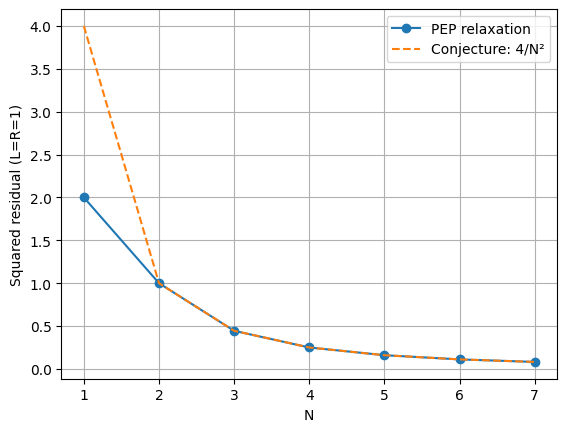

In [6]:
state = json.loads((notebook_dir / "state/feg_b1.json").read_text())
rows = state["sweep_results"]
for row in rows:
    print(f"N={row['N']}: {row['opt_value']:.10f}; N^2*value={row['N']**2*row['opt_value']:.8f}; {row['status']}")
ns = [row["N"] for row in rows]
values = [row["opt_value"] for row in rows]
plt.plot(ns, values, "o-", label="PEP relaxation")
plt.plot(ns, [4/n**2 for n in ns], "--", label="Conjecture: 4/N²")
plt.xlabel("N")
plt.ylabel("Squared residual (L=R=1)")
plt.legend()
plt.grid(True)
plt.show()

For $N=2,\ldots,7$, the values agree with $4/N^2$ to within $10^{-8}$. At $N=1$, the PEP value is $2$. Thus $4L^2R^2/N^2$ is the uniform candidate bound; its tightness at $N=1$ is not conjectured. Scaling $x$ by $R$ and $A$ by $LR$ accounts for the factor $L^2R^2$ when $R>0$; $R=0$ is stationary.

## Dense and relaxed proof solves
The direct primal solve uses CLARABEL defaults at $N=6$. A second fresh solve drops all interpolation multipliers below $10^{-6}$ in the dense result. The complete selected certificate comes from that single solve; all small terms still present in its matrix are retained.

In [7]:
dense_summary = json.loads((notebook_dir / "state/feg_dense.json").read_text())
print("Dense optimum:",dense_summary["opt_value"])
for group in dense_summary["lambda_groups"]:
    active = [(name,value) for name,value in dense_summary["named_dual_values"].items() if dense_summary["constraint_metadata"][name]["group"]==group and value is not None and abs(value)>1e-6]
    print(group, active)
relaxation = [name for name,value in dense_summary["named_dual_values"].items() if name!="initial_condition" and value is not None and abs(value)<1e-6]
print("Dropped constraints:",len(relaxation))

Dense optimum:

 0.1111111198799224
Monotone Operator Inequality [('A monotone:x_1,x_2', 0.2222140757982034), ('A monotone:x_2,x_3', 0.6666422280347524), ('A monotone:x_3,x_4', 1.3332844302514346), ('A monotone:x_4,x_5', 2.2221406729852102), ('A monotone:x_5,x_6', 3.3332109722237133), ('A monotone:x_6,x_star', 0.6666422102225873)]
Lipschitz Continuous Inequality [('A Lipschitz:x_1,x_1/2', 0.05555352251871467), ('A Lipschitz:x_1+1/2,x_2', 0.2222140897797158), ('A Lipschitz:x_2+1/2,x_3', 0.499981684440599), ('A Lipschitz:x_3+1/2,x_4', 0.8888562978571343), ('A Lipschitz:x_4+1/2,x_5', 1.3888379335413479), ('A Lipschitz:x_5+1/2,x_6', 1.999926629647873)]
Dropped constraints: 144


## Lambda and S verification
All inequalities are normalized as $r_{i}\le0$. The fixed-sample numerical identity is
$$\|A(x_{N})\|^2-\mathrm{bound}-\sum_{i}\lambda_{i} r_{i}+S=0.$$
Nonnegative multipliers and $S\succeq0$ establish the direction of the numerical bound. The following code reconstructs the full saved constraint inventory and checks every scalar component. The reverse LDL decomposition retains its full matrix, including small pivots.

In [8]:
import json
import numpy as np
import pepflow as pf
from pepflow.lyapunov_utils import ldl_decompose_with_reversed_basis

b1 = json.loads((notebook_dir / 'state/feg_b1.json').read_text())
dense = json.loads((notebook_dir / 'state/feg_dense.json').read_text())
selected = json.loads((notebook_dir / 'supplementary/b2-selected-raw.json').read_text())
N = selected['N']
ctx, pb, op = get_pep_setup(N, {})
ctx.set_as_current()
pm = pf.ExpressionManager(ctx, resolve_parameters={'L': sp.Integer(1), 'R': sp.Integer(1)})
basis = ctx.basis_vectors()
assert [str(v) for v in basis] == selected['basis_vectors']
assert [str(v) for v in ctx.basis_scalars()] == selected['basis_scalars']
entries = [(c, 'initial', None, None) for c in pb.init_conditions]
for owner in [*ctx.func_to_triplets, *ctx.oper_to_duplets]:
    groups = ctx.get_constraint_data(owner)
    entries.extend((c, 'interpolation', str(owner), str(group)) for group, cs in groups.sc_dict.items() for c in cs)
    entries.extend((c, 'interpolation', str(owner), str(group)) for group, c in groups.psd_dict.items())
assert {c.name for c, *_ in entries} == set(selected['named_dual_values']) == set(selected['constraint_metadata'])
S_array = np.asarray(selected['S_matrix'], dtype=float)
S_labeled = pf.MatrixWithNames(S_array, selected['S_row_names'], selected['S_col_names'])
D, ell = ldl_decompose_with_reversed_basis(S_labeled, basis, print_output=False)
E = np.asarray([pm.eval_vector(v).coords for v in ell], dtype=float)
S_numeric = sum((float(D[i,j])*ell[i]*ell[j] for i,j in np.ndindex(D.shape)), pf.Scalar.zero())
weighted = pf.Scalar.zero()
inequality_duals = []
for c, origin, owner_name, group in entries:
    meta = selected['constraint_metadata'][c.name]
    assert meta['origin'] == origin and meta['owner'] == owner_name and meta['group'] == group
    assert meta['comparator'] == c.cmp.value
    assert isinstance(c, pf.ScalarConstraint) and meta['kind'] == 'scalar' and meta['shape'] == []
    value = selected['named_dual_values'][c.name]
    if meta['relaxed']:
        assert value is None and c.name in selected['relaxed_constraints']
        continue
    assert value is not None and np.isfinite(value)
    residual = c.lhs-c.rhs
    if c.cmp in (pf.Comparator.GE, pf.Comparator.SEQ):
        residual = -residual
    weighted += float(value)*residual
    if c.cmp != pf.Comparator.EQ:
        inequality_duals.append(value)
diff = pb.performance_metric-selected['opt_value']-weighted+S_numeric
checked = pm.eval_scalar(diff)
def max_abs(a):
    return float(np.max(np.abs(np.asarray(a,dtype=float)),initial=0))
residuals = dict(identity_gram_max_abs=max_abs(checked.inner_prod_coords),identity_func_max_abs=max_abs(checked.func_coords),identity_offset_abs=max_abs(checked.offset),S_reconstruction_max_abs=max_abs(E.T@D@E-S_array),dense_relaxed_gap=abs(dense['opt_value']-selected['opt_value']),minimum_scalar_inequality_dual=min(inequality_duals),minimum_S_eigenvalue=float(np.linalg.eigvalsh(S_array).min()),minimum_matrix_inequality_eigenvalue=0.0)
assert selected['solver_status']=='optimal'
assert all(residuals[k]<=1e-5 for k in ('identity_gram_max_abs','identity_func_max_abs','identity_offset_abs','dense_relaxed_gap'))
assert np.allclose(E.T@D@E,S_array,atol=1e-4,rtol=1e-5)
assert np.allclose(S_array,S_array.T,atol=1e-6,rtol=0)
assert residuals['minimum_S_eigenvalue']>=-1e-6 and min(inequality_duals)>=-1e-6
assert abs(selected['opt_value']-4/N**2)<1e-5
print('Dense/selected:',dense['opt_value'],selected['opt_value'],'removed:',len(selected['relaxed_constraints']))
print('Basis:',selected['basis_vectors'])
print('LDL diagonal:',np.diag(D))
print('Full certificate checks:',residuals)
pf.pprint_labeled_matrix(pf.MatrixWithNames(E.T@D@E,selected['basis_vectors'],selected['basis_vectors']))
pf.pprint_labeled_matrix(pf.MatrixWithNames(np.asarray(checked.inner_prod_coords),selected['basis_vectors'],selected['basis_vectors']))



Dense/selected:

 0.1111111198799224 0.11111111913421273 removed: 144
Basis: ['x_1/2', 'x_star', 'A(x_1/2)', 'A(x_1)', 'A(x_1+1/2)', 'A(x_2)', 'A(x_2+1/2)', 'A(x_3)', 'A(x_3+1/2)', 'A(x_4)', 'A(x_4+1/2)', 'A(x_5)', 'A(x_5+1/2)', 'A(x_6)']
LDL diagonal: [1.00045833e+00 7.51153006e-09 2.76501551e-08 7.48731479e-09
 3.51615286e-08 6.59481809e-09 2.70457645e-08 5.40293328e-09
 1.88429287e-08 4.96182345e-09 1.18374812e-08 2.26313258e-09
 9.84068699e-09 9.28986423e-09]
Full certificate checks: {'identity_gram_max_abs': 7.512999260122765e-09, 'identity_func_max_abs': 0.0, 'identity_offset_abs': 6.564890756011188e-09, 'S_reconstruction_max_abs': 5.551115123125783e-17, 'dense_relaxed_gap': 7.457096606877656e-10, 'minimum_scalar_inequality_dual': 0.05556830706343723, 'minimum_S_eigenvalue': 7.343470692425838e-10, 'minimum_matrix_inequality_eigenvalue': 0.0}


C:\Users\Jack\Documents\GitHub\PEPFlow\examples_peppy\_evaluations\20260923T140754Z_paper5_pgm_sos_6x5_isolation1\feg\r02\supplementary\approved\pepflow\pep_context.py:172: UserWarning:

The provided name was already used. The older PEPContext will be overwritten. PEPBuilders constructed with the older PEPContext should be remade.



<IPython.core.display.Math object>

<IPython.core.display.Math object>

### Initial formula search
The sparse pattern suggests monotonicity coefficients $4k(k+1)/N^2$, a final root coefficient $4/N$, and Lipschitz coefficients $2(k+1)^2/N^2$. The rank-one matrix suggests $(2(x_{0}-x_{\star})/N-A(x_{N}))^2$ at $L=R=1$. These guesses are compared against this same certificate below, with tolerance $10^{-4}$. Target-specific references were excluded by the clean-room rules.

In [9]:
# Initial closed-form guesses derived from the selected nonzero pattern.
from fractions import Fraction
candidate = {'initial_condition': 4/N**2}
for k in range(1,N):
    candidate[f'A monotone:x_{k},x_{k+1}'] = 4*k*(k+1)/N**2
candidate[f'A monotone:x_{N},x_star'] = 4/N
candidate['A Lipschitz:x_1,x_1/2'] = 2/N**2
for k in range(1,N):
    candidate[f'A Lipschitz:x_{k}+1/2,x_{k+1}'] = 2*(k+1)**2/N**2
lambda_error = max(abs(selected['named_dual_values'][name]-v) for name,v in candidate.items())
S_guess = (2/N*(ctx['x_0']-ctx['x_star'])-op(ctx[f'x_{N}']))**2
S_guess_eval = pm.eval_scalar(S_guess)
S_guess_error = max_abs(S_guess_eval.inner_prod_coords-S_array)
for name,v in selected['named_dual_values'].items():
    if v is not None:
        print(name, v, 'rational inspection:', Fraction(v).limit_denominator(1000))
print('Candidate comparison errors:',lambda_error,S_guess_error)
print('Atol=1e-4 matches:',lambda_error<=1e-4,S_guess_error<=1e-4)
print('Analytic full-PEP proof: unresolved. Numerical certificate: verified.')
pf.pprint_labeled_matrix(pf.MatrixWithNames(np.asarray(S_guess_eval.inner_prod_coords),selected['basis_vectors'],selected['basis_vectors']))


initial_condition 0.11111112569910349 rational inspection: 1/9
A monotone:x_1,x_2 0.22227319498944406 rational inspection: 2/9
A monotone:x_2,x_3 0.6668195130842369 rational inspection: 2/3
A monotone:x_3,x_4 1.3336389582386639 rational inspection: 1331/998
A monotone:x_4,x_5 2.2227315150486944 rational inspection: 1936/871
A monotone:x_5,x_6 3.3340972127835244 rational inspection: 1457/437
A monotone:x_6,x_star 0.6668194526134993 rational inspection: 2/3
A Lipschitz:x_1,x_1/2 0.05556830706343723 rational inspection: 1/18
A Lipschitz:x_1+1/2,x_2 0.2222731844438772 rational inspection: 2/9
A Lipschitz:x_2+1/2,x_3 0.5001146301473184 rational inspection: 1/2
A Lipschitz:x_3+1/2,x_4 0.8890926343346541 rational inspection: 481/541
A Lipschitz:x_4+1/2,x_5 1.3892071926750234 rational inspection: 1210/871
A Lipschitz:x_5+1/2,x_6 2.000458325092437 rational inspection: 2
Candidate comparison errors: 0.0007638794501909629 0.0004583265227982025
Atol=1e-4 matches: False False
Analytic full-PEP proo

<IPython.core.display.Math object>

### Block 2 conclusion
The full numerical certificate and reverse LDL reconstruction pass. The simple guesses exceed the required numerical comparison tolerance for the selected certificate, so global lambda and S formulas remain unresolved. Numerical partial-sum exploration may proceed with the verified saved certificate. Neither an analytic full-PEP proof nor a Lyapunov proof is claimed.

### Additional certificate for rank confirmation
An additional complete certificate at $N=8$ uses the same retained-pair recipe and verification code as the selected $N=6$ certificate. Both dense and relaxed solves use CLARABEL defaults. The numerical checks and matching decomposition are retained together in `supplementary/N8/`; $N=6$ remains selected.

In [10]:
confirmation = json.loads((notebook_dir / "supplementary/N8/feg_b2.json").read_text())
print("Confirmation certificate N:",confirmation["N_verify"])
print("Bound:",confirmation["opt_value"],"status:",confirmation["solver_status"])
print("Full-coordinate checks:",confirmation["numerical_checks"]["residuals"])
print("Analytic full-PEP verified:",confirmation["analytic_full_pep_verified"])

Confirmation certificate N: 8
Bound: 0.06250000556044698 status: optimal
Full-coordinate checks: {'identity_gram_max_abs': 2.3087068836263633e-09, 'identity_func_max_abs': 0.0, 'identity_offset_abs': 3.094291448069164e-09, 'S_reconstruction_max_abs': 1.3877787807814457e-17, 'dense_relaxed_gap': 2.7977467009776547e-09, 'minimum_scalar_inequality_dual': 0.03125669107477911, 'minimum_S_eigenvalue': 4.615231404822175e-11, 'minimum_matrix_inequality_eigenvalue': 0.0}
Analytic full-PEP verified: False


## Lyapunov partial sums and rank profile
Define $\operatorname{Mon}(u,v)=-\langle A(u)-A(v),u-v\rangle\le0$ and $\operatorname{Lip}(u,v)=\|A(u)-A(v)\|^2-L^2\|u-v\|^2\le0$. Using the selected numerical nonnegative multipliers $m_{k},\ell_{k}$, set $V_{0}=0$ and
$$V_{k+1}-V_{k}=\ell_{k}\operatorname{Lip}(x_{k+1/2},x_{k+1})+\mathbf{1}_{k\ge1}m_{k}\operatorname{Mon}(x_{k},x_{k+1}).$$
Thus the numerical construction has the nonincreasing sign convention. The terminal root monotonicity contribution and the entire PSD matrix $S$ remain boundary terms. No interpolation contribution is omitted. The initial-condition normalization is handled separately by the final bound.

The same construction has rank two for all nonzero indices at horizons 6 and 8. The formal comparison excludes $V_{0},V_{N}$ at each horizon and uses absolute tolerance $10^{-4}$ in the original Gram coordinates at $L=R=1$. This is numerical discovery evidence, not an arbitrary-horizon proof.

In [11]:
certificate = json.loads((notebook_dir / "state/feg_b2.json").read_text())
REPO_ROOT = repo_root
N_int = certificate["N_verify"]
params_sp: dict[str, pf.NUMERICAL_TYPE] = {"L": sp.Integer(1), "R": sp.Integer(1)}
ctx, pb, obj = get_pep_setup(N_int, params_sp)
pb.set_relaxed_constraints(certificate["relaxed_constraints"])
ctx.set_as_current()

In [12]:
import hashlib
import json
from pathlib import Path
import numpy as np
import sympy as sp
import pepflow as pf
from pepflow.constraint import ScalarConstraint
from pepflow.operator import LinearOperatorTranspose
from pepflow.pep_result import MatrixWithNames
from pepflow.utils import name_to_vector_tuple

certificate_checked = False
if not certificate.get("numerical_certificate_verified", False):
    raise ValueError("Recover or verify the complete numerical certificate in Block 2")
if not certificate.get("closed_form_search", {}).get("completed", False):
    raise ValueError("Complete or recover Block 2's initial closed-form attempt")
certificate_keys = (
    "N_verify", "params_json", "relaxed_constraints",
    "S_matrix", "S_row_names", "S_col_names", "basis_vectors", "basis_scalars",
    "opt_value", "tau_sol", "tau_name", "named_dual_values", "constraint_metadata",
    "normalization", "certificate_provenance", "numerical_checks",
    "numerical_decomposition",
)
payload = {key: certificate[key] for key in certificate_keys}
digest = hashlib.sha256(json.dumps(
    payload, sort_keys=True, separators=(",", ":"), allow_nan=False
).encode("utf-8")).hexdigest()
if digest != certificate["certificate_id"]:
    raise ValueError("Certificate components changed; recover one coherent certificate")
provenance = certificate["certificate_provenance"]
if provenance["pep_type"] != "primal":
    raise ValueError("Recover and verify the certificate's actual dual sign convention")
for relative_path, expected_hash in provenance["source_hashes"].items():
    source_path = (notebook_dir / relative_path).resolve()
    if not source_path.is_relative_to(notebook_dir):
        raise ValueError("Certificate source path must stay in the selected repository")
    if hashlib.sha256(source_path.read_bytes()).hexdigest() != expected_hash:
        raise ValueError(f"Certificate source changed: {relative_path}")
if not Path(pf.__file__).resolve().is_relative_to(REPO_ROOT):
    raise ValueError("The imported PEPFlow source is not the selected repository")
if N_int != certificate["N_verify"]:
    raise ValueError("Certificate horizon differs from the rebuilt setup")
saved_params = json.loads(certificate["params_json"])
expected_params = {
    key: (sp.Rational(value) if isinstance(value, str) else
          sp.nsimplify(value, rational=True, tolerance=1e-9)
          if isinstance(value, float) else sp.S(value))
    for key, value in saved_params.items()
}
if params_sp != expected_params:
    raise ValueError("Certificate parameters differ from the rebuilt setup")
if not certificate["numerical_checks"]["passed"]:
    raise ValueError("Block 2 numerical checks did not pass")
tol = certificate["numerical_checks"]["tolerances"]

records = [(c, "initial", None, None) for c in pb.init_conditions]
owners = list(ctx.func_to_triplets) + [
    owner for owner in ctx.oper_to_duplets
    if not isinstance(owner, LinearOperatorTranspose)
]
for owner in owners:
    data = ctx.get_constraint_data(owner)
    for group, family in data.sc_dict.items():
        records.extend((c, "interpolation", str(owner), str(group)) for c in family)
    records.extend((c, "interpolation", str(owner), str(group))
                   for group, c in data.psd_dict.items())
constraints_by_name = {c.name: c for c, _, _, _ in records}
if len(constraints_by_name) != len(records):
    raise ValueError("Constraint names must identify one unique contribution")
saved_meta = certificate["constraint_metadata"]
saved_duals = certificate["named_dual_values"]
if set(constraints_by_name) != set(saved_meta) or set(saved_duals) != set(saved_meta):
    raise ValueError("The saved certificate does not cover the rebuilt constraints")
relaxed = set(certificate["relaxed_constraints"])
if set(pb.relaxed_constraints) != relaxed or not relaxed.issubset(constraints_by_name):
    raise ValueError("The selected relaxation differs from the saved certificate")
if pb.ctx is not ctx:
    raise ValueError("The builder and expression context differ")
basis = list(ctx.basis_vectors())
basis_labels = [repr(v) for v in basis]
scalar_labels = [repr(v) for v in ctx.basis_scalars()]
if basis_labels != certificate["basis_vectors"] or scalar_labels != certificate["basis_scalars"]:
    raise ValueError("Certificate coordinate order differs from the rebuilt context")
if certificate["S_row_names"] != basis_labels or certificate["S_col_names"] != basis_labels:
    raise ValueError("S labels do not match the rebuilt basis")
S_array = np.asarray(certificate["S_matrix"], dtype=float)
if S_array.shape != (len(basis), len(basis)) or not np.all(np.isfinite(S_array)):
    raise ValueError("Invalid S shape or entries")
if not np.allclose(S_array, S_array.T, atol=tol["psd_tol"], rtol=0):
    raise ValueError("S is not numerically symmetric")
if len(basis) and np.linalg.eigvalsh((S_array + S_array.T) / 2).min() < -tol["psd_tol"]:
    raise ValueError("S failed the recorded PSD tolerance")
S_sol = MatrixWithNames(S_array, basis_labels, basis_labels)
pm = pf.ExpressionManager(ctx, resolve_parameters=params_sp)
S_scalar = sum((float(S_array[i, j]) * basis[i] * basis[j]
                for i, j in np.ndindex(S_array.shape)), pf.Scalar.zero())

weighted_terms = {}
interpolation_terms = {}
interpolation_pairs = {}
extra_terms = {}
extra_duals = {}
for constraint, origin, owner, group in records:
    name = constraint.name
    kind = "scalar" if isinstance(constraint, ScalarConstraint) else "psd"
    residual = constraint.lhs - constraint.rhs
    shape = [] if kind == "scalar" else list(np.shape(residual))
    expected_meta = dict(origin=origin, owner=owner, group=group, kind=kind,
                         comparator=constraint.cmp.value, shape=shape,
                         relaxed=name in relaxed)
    if any(saved_meta[name].get(key) != value for key, value in expected_meta.items()):
        raise ValueError(f"Constraint metadata changed: {name}")
    value = saved_duals[name]
    if name in relaxed:
        if value is not None:
            raise ValueError(f"A relaxed constraint must have no retained multiplier: {name}")
        continue
    if value is None:
        raise ValueError(f"Missing unrelaxed dual: {name}")
    dual = np.asarray(value, dtype=float)
    if list(dual.shape) != shape or not np.all(np.isfinite(dual)):
        raise ValueError(f"Invalid saved dual: {name}")
    # Normalize inequalities to residual <= 0; primal equality duals keep their sign.
    if constraint.cmp.name in ("GE", "SEQ"):
        residual = -residual
    if kind == "scalar":
        if constraint.cmp.name != "EQ" and float(dual) < -tol["dual_tol"]:
            raise ValueError(f"Negative inequality multiplier: {name}")
        contribution = pf.Scalar.zero() + float(dual) * residual
    else:
        if constraint.cmp.name != "EQ" and not np.allclose(dual, dual.T, atol=tol["psd_tol"], rtol=0):
            raise ValueError(f"Nonsymmetric matrix dual: {name}")
        if constraint.cmp.name != "EQ" and dual.size and np.linalg.eigvalsh((dual + dual.T) / 2).min() < -tol["psd_tol"]:
            raise ValueError(f"Matrix dual is not PSD: {name}")
        contribution = sum((float(dual[i, j]) * residual[j, i]
                            for i, j in np.ndindex(dual.shape)), pf.Scalar.zero())
    weighted_terms[name] = contribution
    if origin == "interpolation" and kind == "scalar":
        interpolation_terms[name] = contribution
        try:
            interpolation_pairs[name] = name_to_vector_tuple(name)
        except (ValueError, IndexError):
            interpolation_pairs[name] = None  # Assign this term explicitly when grouping.
    elif name != certificate["tau_name"]:
        extra_terms[name] = contribution
        extra_duals[name] = value

tau_name = certificate["tau_name"]
if (tau_name not in weighted_terms or saved_meta[tau_name]["origin"] != "initial"
        or saved_meta[tau_name]["kind"] != "scalar" or tau_name in relaxed
        or certificate["normalization"]["tau_name"] != tau_name):
    raise ValueError("Missing or inconsistent bound normalization constraint")
if not np.allclose(saved_duals[tau_name], certificate["tau_sol"], atol=tol["dual_tol"], rtol=0):
    raise ValueError("The saved normalization dual is inconsistent")
if not np.isfinite(certificate["opt_value"]) or not np.allclose(
    certificate["normalization"]["bound_value"], certificate["opt_value"],
    atol=tol["identity_atol"], rtol=tol["identity_rtol"]
):
    raise ValueError("The saved bound/normalization is inconsistent")
certificate_diff = (pb.performance_metric - float(certificate["opt_value"])
                    - sum(weighted_terms.values(), pf.Scalar.zero()) + S_scalar)
evaluated_diff = pm.eval_scalar(certificate_diff)
for label, coords in (
    ("Gram", evaluated_diff.inner_prod_coords),
    ("function", evaluated_diff.func_coords),
    ("offset", np.asarray(evaluated_diff.offset)),
):
    if not np.allclose(np.asarray(coords, dtype=float), 0,
                       atol=tol["identity_atol"], rtol=tol["identity_rtol"]):
        raise ValueError(f"Numerical certificate {label} identity failed")
decomposition = certificate["numerical_decomposition"]
D_saved = np.asarray(decomposition["D"], dtype=float)
E_saved = np.asarray(decomposition["ell_coords"], dtype=float)
if decomposition["basis_labels"] != basis_labels or E_saved.ndim != 2:
    raise ValueError("Numerical S decomposition basis differs")
if E_saved.shape[1] != len(basis) or D_saved.shape != (E_saved.shape[0], E_saved.shape[0]):
    raise ValueError("Numerical S decomposition shape differs")
if not np.all(np.isfinite(D_saved)) or not np.all(np.isfinite(E_saved)):
    raise ValueError("Numerical S decomposition contains nonfinite values")
if not np.allclose(E_saved.T @ D_saved @ E_saved, S_array,
                   atol=tol["reconstruction_atol"], rtol=tol["reconstruction_rtol"]):
    raise ValueError("Numerical S decomposition does not reconstruct this certificate")
certificate_checked = True
print("Numerical certificate checked for this N and parameter sample.")


Numerical certificate checked for this N and parameter sample.


In [13]:
# Use the complete S as one terminal PSD piece, including all small pivots.
S_piece_terms = {'terminal_S': S_scalar}
S_assignment = {'terminal_S': 'boundary'}
D = D_saved
E = E_saved
ell = [sum((float(coef)*v for coef,v in zip(row,basis)),pf.Vector.zero()) for row in E]
assert np.allclose(E.T@D@E,S_array,atol=tol['reconstruction_atol'],rtol=tol['reconstruction_rtol'])


In [14]:
grouping_checked = False
rank_tolerance = 1e-4
rank_left, rank_right = 1, 1
group_terms = {name:term for name,term in weighted_terms.items() if name != tau_name}
term_assignment = {}
for name in group_terms:
    if name == f'A monotone:x_{N_int},x_star':
        term_assignment[name] = 'boundary'
    elif name == 'A Lipschitz:x_1,x_1/2':
        term_assignment[name] = 0
    elif name.startswith('A monotone:'):
        point = name.split(':')[1].split(',')[0]
        term_assignment[name] = int(point.split('_')[1])
    elif name.startswith('A Lipschitz:'):
        point = name.split(':')[1].split(',')[0]
        term_assignment[name] = int(point.split('_')[1].split('+')[0])
    else:
        raise ValueError('Unassigned term '+name)
assert set(term_assignment) == set(group_terms)
assert all(t == 'boundary' or t in range(N_int) for t in term_assignment.values())
lyap = [pf.Scalar.zero()]
partial_sum = pf.Scalar.zero()
for step in range(N_int):
    partial_sum += sum((group_terms[name] for name,t in term_assignment.items() if t==step),pf.Scalar.zero())
    partial_sum -= sum((S_piece_terms[name] for name,t in S_assignment.items() if t==step),pf.Scalar.zero())
    lyap.append(partial_sum)
ranks=[]
singular_values=[]
for k,Vk in enumerate(lyap):
    matrix=np.asarray(pm.eval_scalar(Vk).inner_prod_coords,dtype=float)
    spectrum=np.linalg.svd(matrix,compute_uv=False)
    singular_values.append(spectrum.tolist())
    ranks.append(int(np.linalg.matrix_rank(matrix,tol=rank_tolerance)))
    print(f'rank V_{k}: {ranks[-1]}')
    if k==0:
        print()
retained_ranks=ranks[rank_left:N_int+1-rank_right]
print('Interior rank is constant at this N:',len(retained_ranks)>=3 and len(set(retained_ranks))==1,'boundary exclusions:',(rank_left,rank_right))
boundary_names=[name for name,t in term_assignment.items() if t=='boundary']
boundary_S=[name for name,t in S_assignment.items() if t=='boundary']
assert len(boundary_names)<=1 and len(boundary_S)<=1
leftover=sum((group_terms[name] for name in boundary_names),pf.Scalar.zero())-sum((S_piece_terms[name] for name in boundary_S),pf.Scalar.zero())
coverage_diff=lyap[N_int]+leftover-(sum(group_terms.values(),pf.Scalar.zero())-S_scalar)
coverage_residuals=[]
for expr in (coverage_diff,sum(S_piece_terms.values(),pf.Scalar.zero())-S_scalar):
    evaluated=pm.eval_scalar(expr)
    coverage_residuals.append(max(float(np.max(np.abs(np.asarray(coords,dtype=float)),initial=0)) for coords in (evaluated.inner_prod_coords,evaluated.func_coords,np.asarray(evaluated.offset))))
    assert coverage_residuals[-1]<=tol['identity_atol']
for piece in S_piece_terms.values():
    evaluated=pm.eval_scalar(piece)
    assert np.allclose(evaluated.func_coords,0,atol=tol['identity_atol'],rtol=0)
    assert abs(float(evaluated.offset))<=tol['identity_atol']
    assert np.linalg.eigvalsh(np.asarray(evaluated.inner_prod_coords,dtype=float)).min()>=-tol['psd_tol']
for k in range(N_int):
    increment=sum((group_terms[name] for name,t in term_assignment.items() if t==k),pf.Scalar.zero())
    increment-=sum((S_piece_terms[name] for name,t in S_assignment.items() if t==k),pf.Scalar.zero())
    evaluated=pm.eval_scalar(lyap[k+1]-lyap[k]-increment)
    for coords in (evaluated.inner_prod_coords,evaluated.func_coords,np.asarray(evaluated.offset)):
        assert np.allclose(np.asarray(coords,dtype=float),0,atol=tol['identity_atol'],rtol=0)
# Every increment is a sum of nonpositive interpolation residuals with nonnegative multipliers.
# Terminal monotonicity and PSD terms remain boundary obligations; the normalization is separate.
grouping_checked=True
print('Full-coordinate coverage and nonincreasing-sign checks passed:',coverage_residuals)


rank V_0: 0

rank V_1: 2
rank V_2: 2
rank V_3: 2
rank V_4: 2
rank V_5: 2
rank V_6: 2
Interior rank is constant at this N: True boundary exclusions: (1, 1)
Full-coordinate coverage and nonincreasing-sign checks passed: [1.1102230246251565e-16, 0.0]


In [15]:
rank_evidence = json.loads((notebook_dir / "supplementary/rank_search.json").read_text())
summary = rank_evidence["summary"]
print("Confirmed horizons:", summary["confirmed_horizons"], "common rank:", summary["rank"])
print("Fixed boundary exclusions:", summary["boundary_exclusions"], "rank tolerance:", rank_tolerance)
for sample in rank_evidence["samples"]:
    retained = sample["rank_profile"][1:-1]
    assert len(retained)>=3 and set(retained)=={2}
    spectra = sample["singular_values"][1:-1]
    print("N =",sample["N"], "smallest retained singular value =",min(s[1] for s in spectra),"largest discarded =", max(s[2] for s in spectra))

Confirmed horizons: [6, 8] common rank: 2
Fixed boundary exclusions: {'left': 1, 'right': 1} rank tolerance: 0.0001
N = 6 smallest retained singular value = 0.03434310246249507 largest discarded = 3.1704272588127524e-08
N = 8 smallest retained singular value = 0.019317697460068974 largest discarded = 9.25479140368595e-09


### Block 3 conclusion
The selected profile is $[0,2,2,2,2,2,2]$. Both horizons pass full-coordinate certificate, decomposition, step-increment, and coverage checks. Boundary leftovers are one root monotonicity term and one complete PSD piece. Exact formulas and their analytic signs remain obligations for the later proof.

## Identify the vectors composing the Lyapunov function
We use the preceding certificate replay and partial sums from the same saved certificate. Rank confirmation excludes the first and last indices, but reconstruction below includes every index.

In [16]:
b3 = json.loads((notebook_dir/'state/feg_b3.json').read_text())
assert certificate_checked and grouping_checked
assert certificate['certificate_id']==b3['certificate_id']
assert ranks==b3['rank_profile']
rank_search=b3['rank_search']
rank_evidence=json.loads((notebook_dir/rank_search['evidence_path']).read_text())
assert rank_evidence['summary']==rank_search
assert rank_search['status']=='confirmed' and rank_search['confirmed_horizons']==[6,8]
assert rank_search['boundary_exclusions']=={'left':1,'right':1}
for k,Vk in enumerate(lyap):
    value=pm.eval_scalar(Vk)
    for actual,saved in ((value.inner_prod_coords,b3['lyap_inner_prod_coords'][k]),(value.func_coords,b3['lyap_func_coords'][k]),(value.offset,b3['lyap_offsets'][k])):
        assert np.allclose(np.asarray(actual,dtype=float),np.asarray(saved,dtype=float),atol=1e-4,rtol=1e-5)
print('Selected partial sums and cross-horizon evidence replayed; all indices 0 through',N_int,'retained for reconstruction.')


Selected partial sums and cross-horizon evidence replayed; all indices 0 through 6 retained for reconstruction.


### Candidate-vector scan
Candidates include all setup basis vectors, integer and intermediate iterates, operator values, and pairwise differences. Meaningful anchor gaps are listed first. Zero and duplicate coordinate vectors are removed before filtering.

In [17]:
from itertools import combinations
from pepflow.lyapunov_utils import vectors_in_column_space, find_basis_with_sparsest_coefficients, find_symmetric_coefficient_matrix

candidate_pairs=[]
for k in range(1,N_int+1):
    candidate_pairs.extend([(f'A(x_{k})',obj(ctx[f'x_{k}'])),(f'x_{k}-x_0',ctx[f'x_{k}']-ctx['x_0'])])
base=list(ctx.basis_vectors())+[ctx[f'x_{k}'] for k in range(N_int+1)]+[ctx['x_star']]+[ctx[f'x_{k}+1/2'] for k in range(1,N_int)]
candidate_pairs.extend((str(v),v) for v in base)
candidate_pairs.extend((f'({u})-({v})',u-v) for u,v in combinations(base,2))
candidates=[]
labels_by_id={}
seen_coords=[]
for label,vector in candidate_pairs:
    coords=np.asarray(pm.eval_vector(vector).coords,dtype=float)
    if np.linalg.norm(coords)<=1e-6 or any(np.allclose(coords,old,atol=1e-8,rtol=0) for old in seen_coords):
        continue
    candidates.append(vector)
    labels_by_id[id(vector)]=label
    seen_coords.append(coords)
print('Deduplicated nonzero candidates:',len(candidates))


Deduplicated nonzero candidates: 360


In [18]:
spanning_by_k={}
for k in range(1,N_int+1):
    in_col=vectors_in_column_space(lyap[k],candidates,pep_context=ctx,resolve_parameters=params_sp,rtol=1e-4,atol=1e-4)
    spanning_by_k[k]=in_col
    print(f'V_{k} column-space candidates:')
    for vector in in_col:
        print('  '+labels_by_id[id(vector)])


V_1 column-space candidates:
  A(x_1)
  x_1-x_0
  A(x_1/2)
  (x_1/2)-(x_1+1/2)
  (A(x_1/2))-(A(x_1))
  (x_1)-(x_1+1/2)
V_2 column-space candidates:
  A(x_2)
  x_2-x_0
  (x_1/2)-(x_2)
  (x_1/2)-(x_2+1/2)
  (x_2)-(x_2+1/2)


V_3 column-space candidates:
  A(x_3)
  x_3-x_0
  (x_1/2)-(x_3)
  (x_1/2)-(x_3+1/2)
  (x_3)-(x_3+1/2)
V_4 column-space candidates:
  A(x_4)
  x_4-x_0
  (x_1/2)-(x_4)
  (x_1/2)-(x_4+1/2)
  (x_4)-(x_4+1/2)


V_5 column-space candidates:
  A(x_5)
  x_5-x_0
  (x_1/2)-(x_5)
  (x_1/2)-(x_5+1/2)
  (x_5)-(x_5+1/2)
V_6 column-space candidates:
  A(x_6)
  x_6-x_0
  (x_1/2)-(x_6)


### Selected basis pattern
The actual sparse-basis search is shown below. We then use a common basis across all nonzero indices: the residual and the displacement from the initial point. This basis is slightly less sparse than some search choices, but has one consistent recurrence interpretation and also applies at the terminal index.

In [19]:
search_results={}
search_tolerances=dict(zero_tol=1e-6,indep_tol=1e-7,span_tol=1e-5)
for k in range(1,N_int+1):
    chosen,C=find_basis_with_sparsest_coefficients(lyap[k],spanning_by_k[k],pep_context=ctx,resolve_parameters=params_sp,zero_tol=1e-6,indep_tol=1e-7,span_tol=1e-5)
    assert len(chosen)==ranks[k]
    selected_labels=[labels_by_id[id(v)] for v in chosen]
    search_results[k]=dict(labels=selected_labels,matrix=C.tolist())
    print(f'k={k}, rank {ranks[k]}: sparse basis: {selected_labels}')
    print(f'  zero coefficients: {int(np.sum(np.abs(C)<1e-6))}/{C.size}')



k=1, rank 2: sparse basis: ['x_1-x_0', '(A(x_1/2))-(A(x_1))']
  zero coefficients: 2/4


k=2, rank 2: sparse basis: ['x_2-x_0', '(x_2)-(x_2+1/2)']
  zero coefficients: 2/4
k=3, rank 2: sparse basis: ['x_3-x_0', '(x_3)-(x_3+1/2)']
  zero coefficients: 2/4


k=4, rank 2: sparse basis: ['x_4-x_0', '(x_4)-(x_4+1/2)']
  zero coefficients: 2/4


k=5, rank 2: sparse basis: ['x_5-x_0', '(x_5)-(x_5+1/2)']
  zero coefficients: 2/4
k=6, rank 2: sparse basis: ['A(x_6)', 'x_6-x_0']
  zero coefficients: 1/4


The adopted ordered template is
$$\mathcal B_{k}=[A(x_{k}),x_{k}-x_{0}],\qquad 1\le k\le N.$$
At $k=0$, $V_{0}=0$ uses the empty basis. Independence and reconstruction are checked at each index, including $k=N$.

In [20]:
def V_k_basis(k):
    if k==0:
        return []
    return [obj(ctx[f'x_{k}']),ctx[f'x_{k}']-ctx['x_0']]


def V_k_basis_labels(k):
    return [] if k==0 else [f'A(x_{k})',f'x_{k}-x_0']


for k in range(N_int+1):
    chosen=V_k_basis(k)
    matrix=np.column_stack([pm.eval_vector(v).coords for v in chosen]).astype(float) if chosen else np.zeros((len(ctx.basis_vectors()),0))
    assert int(np.linalg.matrix_rank(matrix,tol=1e-7))==len(chosen)==ranks[k]
    print(f'k={k}: rank {ranks[k]} basis {V_k_basis_labels(k)}')


k=0: rank 0 basis []
k=1: rank 2 basis ['A(x_1)', 'x_1-x_0']
k=2: rank 2 basis ['A(x_2)', 'x_2-x_0']
k=3: rank 2 basis ['A(x_3)', 'x_3-x_0']
k=4: rank 2 basis ['A(x_4)', 'x_4-x_0']
k=5: rank 2 basis ['A(x_5)', 'x_5-x_0']
k=6: rank 2 basis ['A(x_6)', 'x_6-x_0']


### Coefficient matrices
The order is residual first, anchor displacement second. Symmetric off-diagonal entries contribute twice. Function-value and constant terms are absent, as checked below. The printed matrices are numerical data at $N=6$, not exact all-horizon formulas.

In [21]:
coeff_by_k={}
coefficient_residuals={}
required_indices=list(range(N_int+1))
for k in required_indices:
    chosen=V_k_basis(k)
    value=pm.eval_scalar(lyap[k])
    target=np.asarray(value.inner_prod_coords,dtype=float)
    if chosen:
        matrix=np.column_stack([pm.eval_vector(v).coords for v in chosen]).astype(float)
        C=find_symmetric_coefficient_matrix(lyap[k],chosen,pep_context=ctx,resolve_parameters=params_sp,indep_tol=1e-7,span_tol=1e-5)
        residual=float(np.linalg.norm(matrix@C@matrix.T-target,ord='fro'))
    else:
        C=np.zeros((0,0))
        residual=float(np.linalg.norm(target,ord='fro'))
    assert np.array_equal(C,C.T)
    assert residual<=1e-5*max(1.0,np.linalg.norm(target,ord='fro'))
    assert np.allclose(value.func_coords,0,atol=1e-5,rtol=0) and abs(float(value.offset))<=1e-5
    coeff_by_k[k]=C
    coefficient_residuals[k]=residual
    print(f'k={k}: reconstruction residual {residual:.3g}; function coordinates {value.func_coords}; offset {value.offset}')
    if chosen:
        pf.pprint_labeled_matrix(pf.MatrixWithNames(C,V_k_basis_labels(k),V_k_basis_labels(k)))


k=0: reconstruction residual 0; function coordinates []; offset 0.0
k=1: reconstruction residual 1.96e-17; function coordinates []; offset 0


<IPython.core.display.Math object>

k=2: reconstruction residual 1.89e-08; function coordinates []; offset 0


<IPython.core.display.Math object>

k=3: reconstruction residual 2.58e-08; function coordinates []; offset 0


<IPython.core.display.Math object>

... (2 outputs left out)

k=5: reconstruction residual 4.98e-08; function coordinates []; offset 0

<IPython.core.display.Math object>

k=6: reconstruction residual 5.51e-08; function coordinates []; offset 0


<IPython.core.display.Math object>

In [22]:
def V_k_structure(k):
    vectors=V_k_basis(k)
    C=coeff_by_k[k]
    return sum((float(C[i,j])*vectors[i]*vectors[j] for i,j in np.ndindex(C.shape)),pf.Scalar.zero())


component_residuals={}
for k in required_indices:
    diff=pm.eval_scalar(V_k_structure(k)-lyap[k])
    target=pm.eval_scalar(lyap[k])
    component_residuals[str(k)]={}
    for name,residual,part in (('gram',diff.inner_prod_coords,target.inner_prod_coords),('function',diff.func_coords,target.func_coords),('offset',diff.offset,target.offset)):
        error=float(np.max(np.abs(np.asarray(residual,dtype=float)),initial=0))
        scale=float(np.max(np.abs(np.asarray(part,dtype=float)),initial=0))
        assert error<=1e-4+1e-5*scale
        component_residuals[str(k)][name]=error
print('Every index passes full-expression reconstruction:',component_residuals)


Every index passes full-expression reconstruction:

 {'0': {'gram': 0.0, 'function': 0.0, 'offset': 0.0}, '1': {'gram': 1.3877787807814457e-17, 'function': 0.0, 'offset': 0.0}, '2': {'gram': 1.0952467932590082e-08, 'function': 0.0, 'offset': 0.0}, '3': {'gram': 1.5489513477406902e-08, 'function': 0.0, 'offset': 0.0}, '4': {'gram': 2.3334075449632508e-08, 'function': 0.0, 'offset': 0.0}, '5': {'gram': 3.1022639013222886e-08, 'function': 0.0, 'offset': 0.0}, '6': {'gram': 3.1022639013222886e-08, 'function': 0.0, 'offset': 0.0}}


### Block 4 conclusion
The full interior structure is
$$V_{k}=c_{00}(k,N,L)\|A(x_{k})\|^2+2c_{01}(k,N,L)\langle A(x_{k}),x_{k}-x_{0}\rangle+c_{11}(k,N,L)\|x_{k}-x_{0}\|^2.$$
There are no function-value or constant terms. The initial value is $V_{0}=0$. At $k=N$ the same basis uses unknown coefficients $d_{00},d_{01},d_{11}$ until their relationship to the interior coefficients is established.

All numerical reconstructions pass, including both endpoints. Exact coefficient formulas are unresolved. Block 5 must derive them and prove the step, base, and terminal identities with the required signs and normalization.

## Closed-form Lyapunov function and exact identities

In [23]:
b4 = json.loads((notebook_dir/'state/feg_b4.json').read_text())
assert b4['certificate_id']==certificate['certificate_id']
assert b4['numerical_reconstruction']['certificate_id']==certificate['certificate_id']
assert certificate_checked and grouping_checked
assert set(component_residuals)=={str(k) for k in range(N_int+1)}
for key,value in b4['coeff_by_k'].items():
    expected_matrix=np.asarray(value,dtype=float).reshape(coeff_by_k[int(key)].shape)
    assert np.allclose(coeff_by_k[int(key)],expected_matrix,atol=1e-4,rtol=1e-5)
print('B4 input unchanged; complete certificate and numerical structure were rechecked in the preceding cells.')
print('Exact coefficient functions to derive:',[u['name'] for u in b4['unresolved_coefficients']])


B4 input unchanged; complete certificate and numerical structure were rechecked in the preceding cells.


Exact coefficient functions to derive: ['c00', 'c01', 'c11', 'd00', 'd01', 'd11']


### Symbolic recursion context and coefficient derivation
We retain all three unknown symmetric coefficients in the basis $[A(x_{k}),x_{k}-x_{0}]$, together with unknown Lipschitz and monotonicity multipliers. The equations below require all Gram, function-value, and constant components to vanish. The resulting family has one scale parameter; choosing it to match the terminal normalization gives the stated nonzero certificate.

In [24]:
import sympy as sp
import pepflow as pf


def symbolic_components(expression, manager):
    value=manager.eval_scalar(pf.Scalar.zero()+expression,sympy_mode=True)
    return (sp.Matrix(value.inner_prod_coords).applyfunc(sp.simplify),sp.Matrix(list(value.func_coords)).applyfunc(sp.simplify),sp.simplify(sp.sympify(value.offset)))


def verify_exact(name,expression,manager,context):
    gram,functions,offset=symbolic_components(expression,manager)
    assert all(v==0 for v in [*gram,*functions,offset]),name
    labels=[str(v) for v in context.basis_vectors()]
    pf.pprint_labeled_matrix(pf.MatrixWithNames(np.asarray(gram,dtype=object),labels,labels))
    print(name,'Gram residual: zero; function coordinates:',functions,'offset:',offset)
    return True


k_symbol,N_symbol=sp.symbols('k N',integer=True,positive=True)
L_symbol=sp.symbols('L',positive=True)
R_symbol=sp.symbols('R',nonnegative=True)
Kp=pf.Parameter('k_symbolic')
Np=pf.Parameter('N_symbolic')
Lp=pf.Parameter('L_symbolic')
Rp=pf.Parameter('R_symbolic')
ctx_step=pf.PEPContext('feg_symbolic_step').set_as_current()
A_step=pf.LipschitzMonotoneOperator(is_basis=True,tags=['A_{step}'],L=Lp)
x_anchor=pf.Vector(is_basis=True,tags=['x_{0}'])
x_current=pf.Vector(is_basis=True,tags=['x_{k}'])
g_current=A_step(x_current)
x_half=x_current+(x_anchor-x_current)/(Kp+1)-Kp/((Kp+1)*Lp)*g_current
x_half.add_tag('x_{k+1/2}')
g_half=A_step(x_half)
x_next=x_current+(x_anchor-x_current)/(Kp+1)-g_half/Lp
x_next.add_tag('x_{k+1}')
g_next=A_step(x_next)
unknown_names=['a_k','b_k','c_k','a_next','b_next','c_next','mu','nu']
unknown_symbols=dict(zip(unknown_names,sp.symbols('a_k b_k c_k a_next b_next c_next mu nu',real=True)))
unknown_parameters={name:pf.Parameter(name) for name in unknown_names}
def ansatz(a,b,c,g,x):
    return a*g**2+2*b*g*(x-x_anchor)+c*(x-x_anchor)**2
V_unknown=ansatz(unknown_parameters['a_k'],unknown_parameters['b_k'],unknown_parameters['c_k'],g_current,x_current)
V_next_unknown=ansatz(unknown_parameters['a_next'],unknown_parameters['b_next'],unknown_parameters['c_next'],g_next,x_next)
mon_step=-(g_next-g_current)*(x_next-x_current)
lip_step=(g_next-g_half)**2-Lp**2*(x_next-x_half)**2
unknown_LHS=V_next_unknown-V_unknown
unknown_RHS=unknown_parameters['mu']*mon_step+unknown_parameters['nu']*lip_step
unknown_diff=unknown_LHS-unknown_RHS
symbolic_mapping={'k_symbolic':k_symbol,'N_symbolic':N_symbol,'L_symbolic':L_symbol,**unknown_symbols}
pm_unknown=pf.ExpressionManager(ctx_step,resolve_parameters=symbolic_mapping)
gram_unknown,func_unknown,offset_unknown=symbolic_components(unknown_diff,pm_unknown)
equations=[v for v in [*gram_unknown,*func_unknown,offset_unknown] if v!=0]
solution=sp.solve(equations,[unknown_symbols[name] for name in unknown_names[:-1]],dict=True)
print('Coefficient-equation solution:',solution)
assert len(solution)==1


Coefficient-equation solution: [{a_k: k**2*nu/(k**2 + 2*k + 1), a_next: nu, b_k: L*k*nu/(k**2 + 2*k + 1), b_next: L*nu/(k + 1), c_k: 0, c_next: 0, mu: 2*L*k*nu/(k + 1)}]


### Derived Lyapunov coefficients
The equations give $a_{k}=k^{2}\nu/(k+1)^{2}$, $b_{k}=Lk\nu/(k+1)^{2}$, $c_{k}=0$, $a_{k+1}=\nu$, $b_{k+1}=L\nu/(k+1)$, $c_{k+1}=0$, and $\mu=2Lk\nu/(k+1)$. Selecting $\nu=2(k+1)^{2}/N^{2}$ produces a consistent sequence across steps:
$$V_{k}=\frac{2k^{2}}{N^{2}}\|A(x_{k})\|^{2}+\frac{4kL}{N^{2}}\langle A(x_{k}),x_{k}-x_{0}\rangle.$$
The initial value is $V_{0}=0$; the same nonzero-index formula also supplies the terminal coefficients. The next sections verify the original step identity, the separate base case, and the target normalization exactly.

## Symbolic Step Recursion Verification

For $k\ge1$ and $N\ge k+1$, verify
$$V_{k+1}-V_{k}=\frac{4Lk(k+1)}{N^{2}}M(x_{k},x_{k+1})+\frac{2(k+1)^{2}}{N^{2}}Q(x_{k+1/2},x_{k+1}).$$
The residual $\mathrm{LHS}-\mathrm{RHS}$ must simplify to zero in every component. There are no additional square or scalar terms in this step.

In [25]:
# Choose the nonzero scale nu_k=2(k+1)^2/N^2 to target the desired bound.
nu_choice=2*(k_symbol+1)**2/N_symbol**2
resolved={name:sp.simplify(solution[0].get(symbol, symbol).subs(unknown_symbols['nu'],nu_choice)) for name,symbol in unknown_symbols.items()}
print('Resolved coefficients and local multipliers:',resolved)
expected={'a_k':2*k_symbol**2/N_symbol**2,'b_k':2*k_symbol*L_symbol/N_symbol**2,'c_k':sp.Integer(0),'a_next':2*(k_symbol+1)**2/N_symbol**2,'b_next':2*(k_symbol+1)*L_symbol/N_symbol**2,'c_next':sp.Integer(0),'mu':4*k_symbol*(k_symbol+1)*L_symbol/N_symbol**2,'nu':nu_choice}
assert all(sp.simplify(resolved[name]-formula)==0 for name,formula in expected.items())
assert sp.simplify(resolved['a_next']-resolved['a_k'].subs(k_symbol,k_symbol+1))==0
assert sp.simplify(resolved['b_next']-resolved['b_k'].subs(k_symbol,k_symbol+1))==0
# Original unknown Scalar identity is re-evaluated after the derived substitution.
pm_step=pf.ExpressionManager(ctx_step,resolve_parameters={'k_symbolic':k_symbol,'N_symbolic':N_symbol,'L_symbolic':L_symbol,**resolved})
step_LHS=V_next_unknown-V_unknown
step_RHS=unknown_parameters['mu']*mon_step+unknown_parameters['nu']*lip_step
step_diff=step_LHS-step_RHS
step_verified=verify_exact('Symbolic step',step_diff,pm_step,ctx_step)


Resolved coefficients and local multipliers: {'a_k': 2*k**2/N**2, 'b_k': 2*L*k/N**2, 'c_k': 0, 'a_next': 2*(k + 1)**2/N**2, 'b_next': 2*L*(k + 1)/N**2, 'c_next': 0, 'mu': 4*L*k*(k + 1)/N**2, 'nu': 2*(k + 1)**2/N**2}


<IPython.core.display.Math object>

Symbolic step Gram residual: zero; function coordinates: Matrix(0, 0, []) offset: 0


In [26]:
def exact_coefficients(k,N,L):
    return sp.Matrix([[2*k**2/N**2,2*k*L/N**2],[2*k*L/N**2,0]])


pf.pprint_labeled_matrix(np.asarray(exact_coefficients(k_symbol,N_symbol,L_symbol),dtype=object),['A(x_k)','x_k-x_0'],['A(x_k)','x_k-x_0'],precision=0)
# Compare with numerical sample data without conflating exact proof and solver closeness.
for index in range(1,N_int+1):
    exact=np.asarray(exact_coefficients(sp.Integer(index),sp.Integer(N_int),sp.Integer(1)),dtype=float)
    error=float(np.max(np.abs(exact-coeff_by_k[index])))
    print(f'k={index}: exact/numerical coefficient discrepancy {error:.8g}; match at atol=1e-4: {error<=1e-4}')
print('The exact coefficients follow from symbolic equations and boundary normalization; the selected numerical dual has a slightly different scale and is retained unchanged.')

G_symbol,H_symbol=sp.symbols("G H",real=True)
V_display=2*k_symbol**2/N_symbol**2*G_symbol+4*k_symbol*L_symbol/N_symbol**2*H_symbol
print("V_k with G=||A(x_k)||^2 and H=<A(x_k),x_k-x_0>:",V_display)
print("LaTeX:",sp.latex(V_display))


<IPython.core.display.Math object>

k=1: exact/numerical coefficient discrepancy 1.2751508e-05; match at atol=1e-4: True
k=2: exact/numerical coefficient discrepancy 5.0962222e-05; match at atol=1e-4: True
k=3: exact/numerical coefficient discrepancy 0.00011463015; match at atol=1e-4: False
k=4: exact/numerical coefficient discrepancy 0.00020374545; match at atol=1e-4: False
k=5: exact/numerical coefficient discrepancy 0.00031830379; match at atol=1e-4: False
k=6: exact/numerical coefficient discrepancy 0.00045832509; match at atol=1e-4: False
The exact coefficients follow from symbolic equations and boundary normalization; the selected numerical dual has a slightly different scale and is retained unchanged.
V_k with G=||A(x_k)||^2 and H=<A(x_k),x_k-x_0>: 2*G*k**2/N**2 + 4*H*L*k/N**2
LaTeX: \frac{2 G k^{2}}{N^{2}} + \frac{4 H L k}{N^{2}}


## Base Case and Boundary Symbolic Verification

The base context explicitly uses $x_{1/2}=x_{0}$ and $x_{1}=x_{0}-A(x_{0})/L$. Verify
$$V_{1}-V_{0}=V_{1}=\frac{2}{N^{2}}Q(x_{0},x_{1}),\qquad V_{0}=0.$$
The residual $\mathrm{LHS}-\mathrm{RHS}$ must be zero. Lipschitz continuity gives $V_{1}\le0$.

In [27]:
ctx_base=pf.PEPContext('feg_symbolic_base').set_as_current()
A_base=pf.LipschitzMonotoneOperator(is_basis=True,tags=['A_{base}'],L=Lp)
x0_base=pf.Vector(is_basis=True,tags=['x_{0}'])
xhalf_base=x0_base
xhalf_base.add_tag('x_{1/2}')
g0_base=A_base(x0_base)
x1_base=x0_base-g0_base/Lp
x1_base.add_tag('x_{1}')
g1_base=A_base(x1_base)
base_LHS=2/Np**2*g1_base**2+4*Lp/Np**2*g1_base*(x1_base-x0_base)
base_RHS=2/Np**2*((g1_base-g0_base)**2-Lp**2*(x1_base-x0_base)**2)
base_diff=base_LHS-base_RHS
pm_base=pf.ExpressionManager(ctx_base,resolve_parameters={'N_symbolic':N_symbol,'L_symbolic':L_symbol})
assert xhalf_base is x0_base
base_verified=verify_exact('Symbolic base',base_diff,pm_base,ctx_base)


<IPython.core.display.Math object>

Symbolic base Gram residual: zero; function coordinates: Matrix(0, 0, []) offset: 0


### Boundary Identity Symbolic Verification

For every $N\ge1$, verify
$$\|A(x_{N})\|^{2}-\frac{4L^{2}R^{2}}{N^{2}}=V_{N}+\frac{4L}{N}M(x_{N},x_{\star})-\left\|A(x_{N})-\frac{2L}{N}(x_{0}-x_{\star})\right\|^{2}+\frac{4L^{2}}{N^{2}}\bigl(\|x_{0}-x_{\star}\|^{2}-R^{2}\bigr).$$
The residual $\mathrm{LHS}-\mathrm{RHS}$ must be zero, including its constant component.

In [28]:
ctx_terminal=pf.PEPContext('feg_symbolic_terminal').set_as_current()
A_terminal=pf.LipschitzMonotoneOperator(is_basis=True,tags=['A_{boundary}'],L=Lp)
x0_terminal=pf.Vector(is_basis=True,tags=['x_{0}'])
xN_terminal=pf.Vector(is_basis=True,tags=['x_{N}'])
xs_terminal=A_terminal.set_zero_point('x_{star}')
gN_terminal=A_terminal(xN_terminal)
V_terminal=2*gN_terminal**2+4*Lp/Np*gN_terminal*(xN_terminal-x0_terminal)
mon_terminal=-gN_terminal*(xN_terminal-xs_terminal)
S_terminal=(gN_terminal-2*Lp/Np*(x0_terminal-xs_terminal))**2
init_terminal=(x0_terminal-xs_terminal)**2-Rp**2
boundary_LHS=gN_terminal**2-4*Lp**2*Rp**2/Np**2
boundary_RHS=V_terminal+4*Lp/Np*mon_terminal-S_terminal+4*Lp**2/Np**2*init_terminal
boundary_diff=boundary_LHS-boundary_RHS
pm_terminal=pf.ExpressionManager(ctx_terminal,resolve_parameters={'N_symbolic':N_symbol,'L_symbolic':L_symbol,'R_symbolic':R_symbol})
boundary_verified=verify_exact('Symbolic boundary',boundary_diff,pm_terminal,ctx_terminal)
assert expected['mu'].is_positive and expected['nu'].is_positive
assert (4*L_symbol/N_symbol).is_positive and (4*L_symbol**2/N_symbol**2).is_positive
print('Signs: k>=1, N>=1, L>0; all residual multipliers positive, terminal square subtracted. R>=0.')
print('Base V1<=0, steps V(k+1)<=V(k), terminal identity implies ||A(xN)||^2<=4 L^2 R^2/N^2, including N=1.')


<IPython.core.display.Math object>

Symbolic boundary Gram residual: zero; function coordinates: Matrix(0, 0, []) offset: 0
Signs: k>=1, N>=1, L>0; all residual multipliers positive, terminal square subtracted. R>=0.
Base V1<=0, steps V(k+1)<=V(k), terminal identity implies ||A(xN)||^2<=4 L^2 R^2/N^2, including N=1.


### Sign, domain, and normalization conclusion
For integer $k\ge1$, integer $N\ge1$, and $L>0$, all step, base, and terminal residual multipliers are nonnegative, and all denominators are nonzero. Monotonicity and Lipschitz continuity supply the residual signs; the terminal norm square is subtracted. The initial-distance residual is nonpositive by assumption. Therefore the base identity, step decrease, and terminal identity prove
$$\|A(x_{N})\|^{2}\le4L^{2}R^{2}/N^{2}.$$
The proof handles $N=1$ separately through the base identity, and it also applies when $R=0$. The universal Lyapunov proof is established. The earlier global numerical certificate remains verified at its sampled horizon; a separate analytic global lambda/S-table verification is not claimed.